<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_15.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Basis Functions 2: Ridge and Lasso

##Core Question

In [2]:
## Feel free to skip this cell to the next one.
%pip install jax[cpu]
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt

## Plotting Helper
def plot_mesh(fig, ax, fn,
    x_data, y_data,
    x_range=(-6, -2),
    y_range=(0, 4),
    N=20,
    cmap="Blues_r",
    show_true=True):

    beta0_s = np.linspace(*x_range, N)
    beta1_s = np.linspace(*y_range, N)
    mesh_b0, mesh_b1 = np.meshgrid(beta0_s, beta1_s)
    params = {"beta_0": mesh_b0.flatten(), "beta_1": mesh_b1.flatten()}

    batched_ll = jax.vmap(fn, in_axes=(0, None, None))
    mesh_y = batched_ll(params, x_data, y_data).reshape(N, N)

    contour = ax.contourf(mesh_b0, mesh_b1, mesh_y, levels=50, cmap=cmap)
    fig.colorbar(contour, ax=ax)
    ax.set_xlabel("Beta0")
    ax.set_ylabel("Beta1")

    min_arg = np.argmin(mesh_y)
    min_x, min_y = mesh_b0.flatten()[min_arg], mesh_b1.flatten()[min_arg]
    ax.scatter(min_x, min_y, marker="x", label="Estimated Minimum")

    if show_true:
        ax.scatter(-5, 3, marker="x", label="True Value")

    ax.set_title("Estimate: beta0={:.2f}, beta1={:.2f}".format(min_x, min_y))
    ax.legend()

## Data helper
def sigmoid(x):
    return np.exp(x) / (1 + np.exp(x))

def generate_data(x):
    a = 3  #beta_1
    b = -5  #beta_0
    prob = sigmoid(a*x+b)
    return np.random.uniform() < prob

def generate_dataset(N):
    x_data = np.random.uniform(high=3, size=N)
    y_data = [generate_data(x) for x in x_data]
    y_data = np.array(y_data, dtype=np.float32)
    return x_data, y_data

In [3]:
NUM_DATAPOINTS = 1000
x_data, y_data = generate_dataset(NUM_DATAPOINTS)

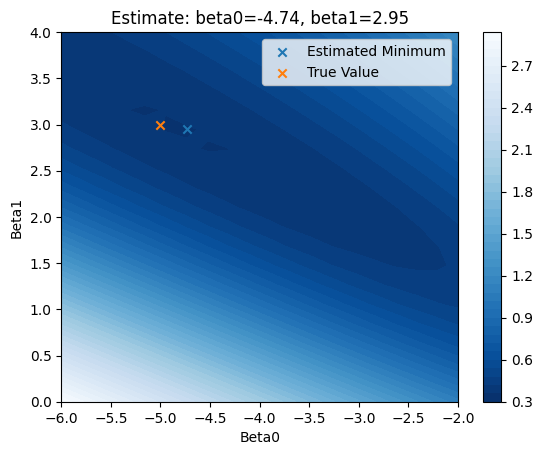

In [4]:
import jax
import jax.numpy as jnp

@jax.jit
def nll(params, xs, ys):
    logit = params["beta_0"] + params["beta_1"] * xs
    probs = jax.nn.sigmoid(logit)
    likelihood = ys * jnp.log(probs) + (1 - ys) * jnp.log(1 - probs)
    # Note we take the average then negative, NOT the sum.
    return -jnp.mean(likelihood)

fig, ax = plt.subplots()
plot_mesh(fig, ax, nll, x_data, y_data, cmap="Blues_r")
plt.show()

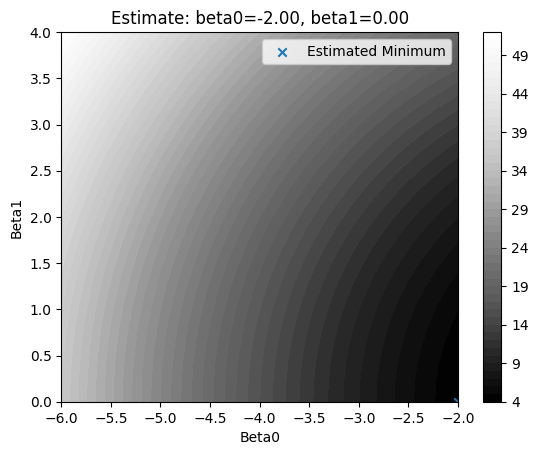

In [5]:
# Question
@jax.jit
def l2_norm(params, xs, ys):
    beta_0 = params["beta_0"]
    beta_1 = params["beta_1"]
    norm = beta_0**2 + beta_1**2  # Fill this in, keep it simple!
    return norm

fig, ax = plt.subplots()
plot_mesh(fig, ax, l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")
plt.show()

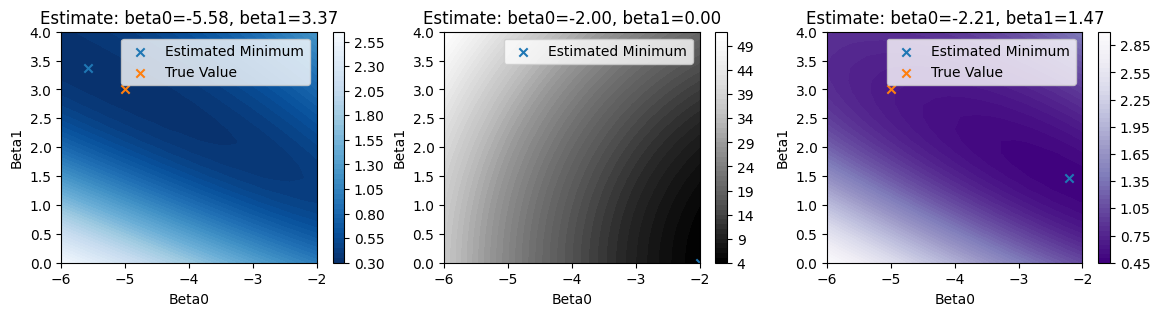

In [17]:
def modified_loss(params, xs, ys, alpha=1e-2):
    return nll(params, xs, ys) + alpha * l2_norm(params, xs, ys)

# Uncomment the next line when asked
x_data, y_data = generate_dataset(NUM_DATAPOINTS)

fig, ax = plt.subplots(ncols=3, figsize=(14, 3))
plot_mesh(fig, ax[0], nll, x_data, y_data, cmap="Blues_r")
plot_mesh(fig, ax[1], l2_norm, x_data, y_data, show_true=False, cmap="Greys_r")
plot_mesh(fig, ax[2], modified_loss, x_data, y_data, cmap="Purples_r")
plt.show()

##Extension Question

In [7]:
# Your code here

# I used Claude and ChatGPT to improve my code and also implement some suggestions they made

from sklearn.linear_model import LogisticRegression, RidgeClassifier
import numpy as np
import matplotlib.pyplot as plt

logistic_coefs = []
ridge_coefs = []

for i in range(50):
    x_data, y_data = generate_dataset(NUM_DATAPOINTS)

    # Your code here
    X = x_data.reshape(-1, 1)

    logistic = LogisticRegression(penalty=None)
    ridge = RidgeClassifier(alpha=1e-2)

    logistic.fit(X, y_data)
    ridge.fit(X, y_data)

    # storing intercept: beta_0 and slope: beta_1
    logistic_coefs.append([logistic.intercept_[0], logistic.coef_[0, 0]])
    ridge_coefs.append([ridge.intercept_[0], ridge.coef_[0]])

Logistic Regression variance: [0.13560432 0.04586223]
Ridge Classifier variance: [0.00099798 0.00038763]


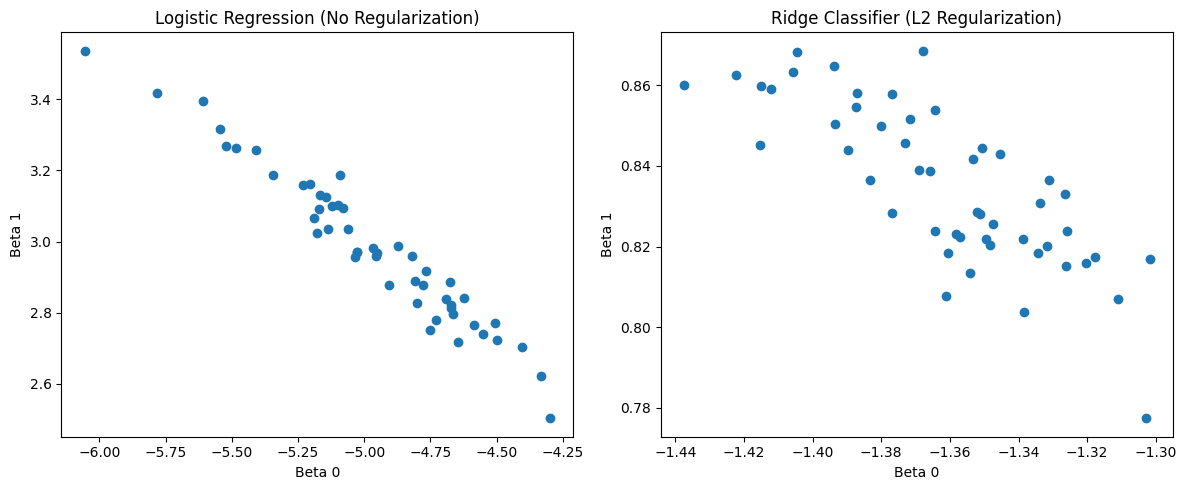

In [8]:
logistic_coefs = np.array(logistic_coefs)
ridge_coefs = np.array(ridge_coefs)

# variance of each parameter
print("Logistic Regression variance:", np.var(logistic_coefs, axis=0))
print("Ridge Classifier variance:", np.var(ridge_coefs, axis=0))

# coefficient estimates
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].scatter(logistic_coefs[:, 0], logistic_coefs[:, 1])
ax[0].set_title("Logistic Regression (No Regularization)")
ax[0].set_xlabel("Beta 0")
ax[0].set_ylabel("Beta 1")
ax[1].scatter(ridge_coefs[:, 0], ridge_coefs[:, 1])
ax[1].set_title("Ridge Classifier (L2 Regularization)")
ax[1].set_xlabel("Beta 0")
ax[1].set_ylabel("Beta 1")
plt.tight_layout()
plt.show()